In [1]:
import osmnx as ox

import pandas as pd
import geopandas as gpd
import shapely
import pyrosm

pd.set_option("display.max_columns", None)

In [3]:
fp = "chile-latest.osm.pbf"
place_name = "Concepción, Chile"

place_string = "_".join(place_name.lower().split(",")[0].split(" "))

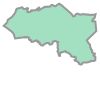

In [4]:
area_gdf = ox.geocode_to_gdf(place_name)
area = area_gdf.geometry.iloc[0]
area

In [7]:
# load the file with all osm data and clip with boundary
osm = pyrosm.OSM(fp, bounding_box=area)

# download the buildings
buildings = osm.get_buildings()
buildings

,addr:city,addr:country,addr:housenumber,addr:housename,addr:postcode,addr:place,addr:street,email,name,opening_hours,operator,phone,visible,website,building,amenity,building:flats,building:levels,craft,height,internet_access,landuse,office,shop,source,start_date,wikipedia,id,timestamp,version,tags,osm_type,geometry,changeset
0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Casino Federación de Estudiantes,NaN,NaN,NaN,True,NaN,yes,restaurant,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,83103963,1559266433,6,NaN,way,"POLYGON ((-73.01369 -36.82376, -73.01358 -36.8...",NaN
1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Vicerrectoría de Asuntos Económicos,NaN,NaN,NaN,True,NaN,yes,NaN,NaN,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,83106230,1560553232,5,NaN,way,"POLYGON ((-73.01423 -36.82134, -73.01417 -36.8...",NaN
2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Facultad de Ciencias,NaN,NaN,NaN,True,NaN,university,NaN,NaN,3,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,83106231,1566618374,8,NaN,way,"POLYGON ((-73.01361 -36.82164, -73.0134 -36.82...",NaN
3,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,True,NaN,yes,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,83106241,1515187883,2,NaN,way,"POLYGON ((-73.01269 -36.82394, -73.01258 -36.8...",NaN
4,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Departamento de Ingeniería Mecánica,NaN,NaN,NaN,True,NaN,university,NaN,NaN,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,83106253,1559412120,4,NaN,way,"POLYGON ((-73.01233 -36.82163, -73.01206 -36.8...",NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5900,Concepción,NaN,NaN,NaN,4030000,NaN,Cochrane,NaN,NaN,NaN,NaN,NaN,True,NaN,church,NaN,NaN,3,NaN,8.4,NaN,NaN,NaN,NaN,NaN,NaN,NaN,10320075,1621317955,3,"{""type"":""multipolygon"",""members"":[{""member_id""...",relation,"POLYGON ((-73.04366 -36.82729, -73.0438 -36.82...",0.0
5901,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,True,NaN,hospital,NaN,NaN,4,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,10462735,1626627751,3,"{""type"":""multipolygon"",""members"":[{""member_id""...",relation,"POLYGON ((-73.0309 -36.81324, -73.03122 -36.81...",0.0
5902,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Dirección de Desarrollo Estudiantil,NaN,NaN,NaN,True,NaN,yes,NaN,NaN,1,NaN,NaN,NaN,NaN,yes,NaN,NaN,NaN,NaN,10591613,1607895392,2,"{""type"":""multipolygon"",""members"":[{""member_id""...",relation,"POLYGON ((-73.01355 -36.82325, -73.01369 -36.8...",0.0
5903,Concepción,NaN,NaN,NaN,NaN,NaN,Avenida Jorge Alessandri,NaN,Escuela de Formación de Carabineros de Concepción,NaN,NaN,NaN,True,NaN,college,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,18623340,1738101264,1,"{""type"":""multipolygon"",""members"":[{""member_id""...",relation,"POLYGON ((-73.06695 -36.79976, -73.06707 -36.7...",0.0


In [ ]:
# load the file with all osm data and clip with boundary
osm = pyrosm.OSM(fp, bounding_box=area)

# download the features
pois = osm.get_pois(custom_filter=tags)

pois = pois.to_crs(32718)
pois.geometry = pois.geometry.centroid
pois = pois.to_crs(4326)

pois = pois[~pois["amenity"].isna()]
pois = pois[pois['amenity'] != 'bench']

pois.lon = pois.geometry.x
pois.lat = pois.geometry.y
pois = pois.rename(columns={"lon": "x", "lat": "y"})

pois = pois[["id", "x", "y", "amenity", "geometry"]]

In [9]:
buildings.building.value_counts().to_dict()

{'yes': 3211,
 'house': 1639,
 'apartments': 383,
 'detached': 167,
 'terrace': 119,
 'residential': 66,
 'university': 61,
 'school': 55,
 'roof': 49,
 'commercial': 42,
 'church': 16,
 'office': 14,
 'hospital': 14,
 'industrial': 12,
 'retail': 9,
 'supermarket': 6,
 'semidetached_house': 5,
 'public': 4,
 'garage': 4,
 'chapel': 4,
 'warehouse': 3,
 'college': 3,
 'train_station': 2,
 'temple': 2,
 'parking': 2,
 'oficinas': 1,
 'hotel': 1,
 'no': 1,
 'garages': 1,
 'synagogue': 1,
 'shed': 1,
 'guardhouse': 1,
 'civic': 1,
 'government': 1,
 'kindergarten': 1,
 'static_caravan': 1,
 'dormitory': 1,
 'stadium': 1}

In [10]:
edges_gdf = gpd.read_file(f"./network/{place_string}.gpkg", layer="edges", encoding="latin-1")

(-36.8623217, -36.7747554)

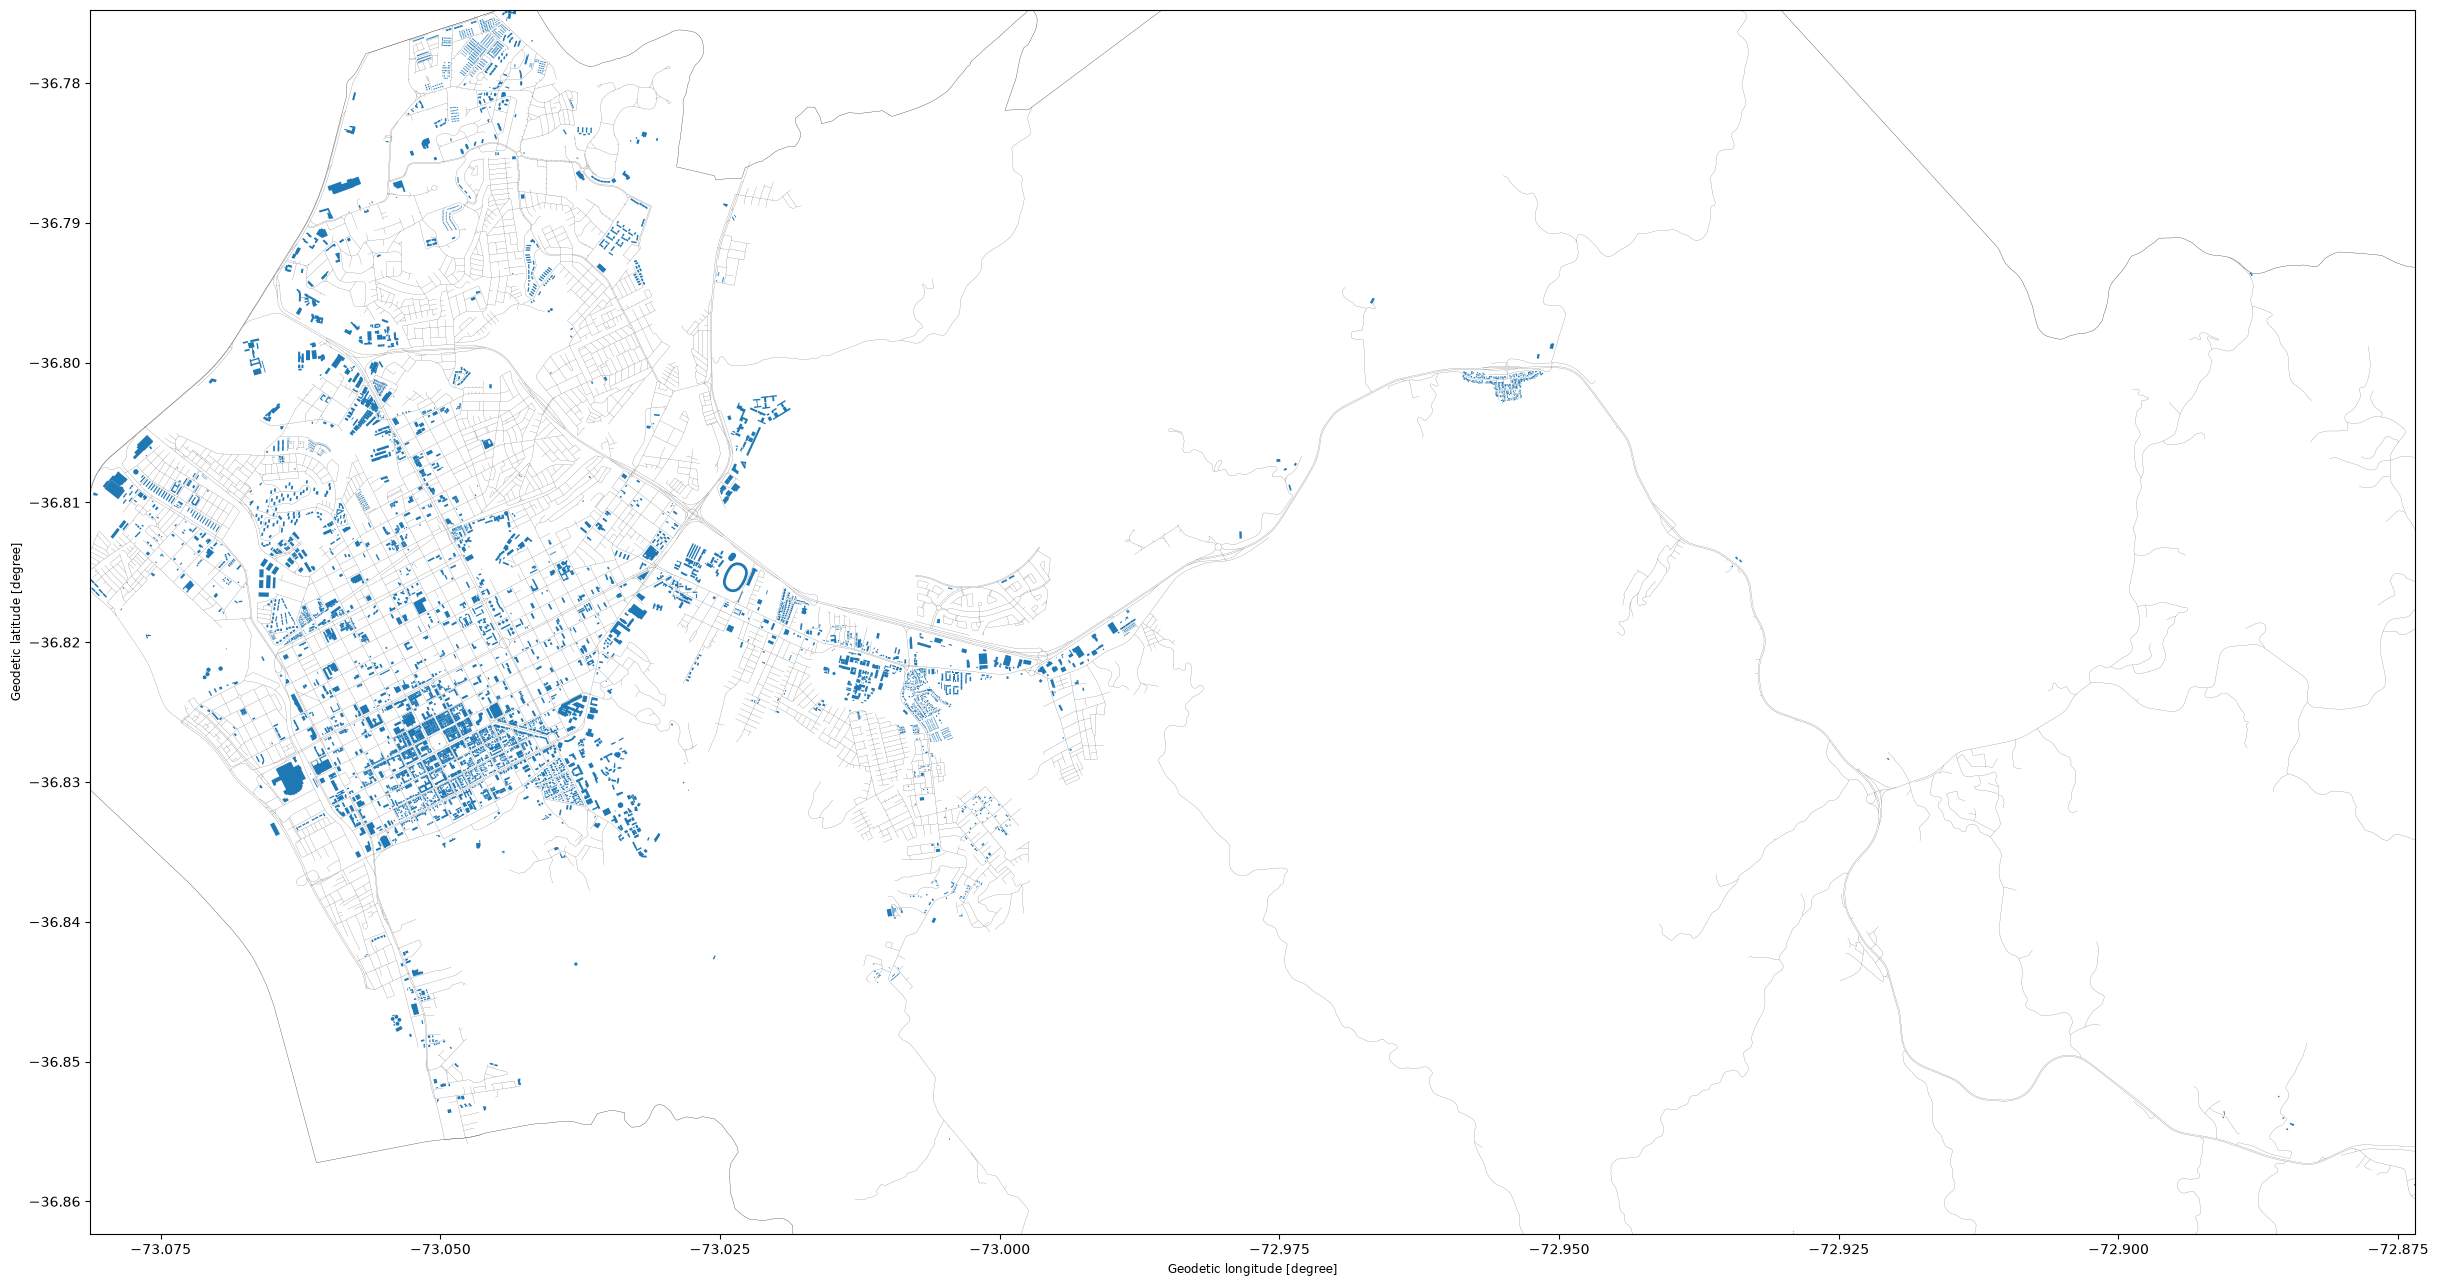

In [13]:
ax = buildings.plot(figsize=(30,30))
edges_gdf.plot(ax=ax, color="black", linewidth=0.1)
area_gdf.plot(ax=ax, color="none", linewidth=0.2)

ax.set_xlim(buildings.total_bounds[0], buildings.total_bounds[2])
ax.set_ylim(buildings.total_bounds[1], buildings.total_bounds[3])

In [155]:
pois.to_parquet(f"pois/pois_{place_string}.parquet")